<a href="https://colab.research.google.com/github/ashishkunche9-lab/blockchain-projects/blob/main/05-mini-wallet/mini_wallet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import json, copy
from cryptography.hazmat.primitives.asymmetric.ed25519 import Ed25519PrivateKey
from cryptography.exceptions import InvalidSignature

# Each account has a key pair, a balance and a transaction counter (nonce)
keys = {n: Ed25519PrivateKey.generate() for n in ["Ravi", "Sita", "Kiran"]}
pubs = {n: k.public_key() for n, k in keys.items()}
balances = {n: 100 for n in keys}
next_nonce = {n: 0 for n in keys}
ledger = []

def payload(tx):
    data = {k: tx[k] for k in ("sender", "to", "amount", "nonce")}
    return json.dumps(data, sort_keys=True).encode()

def make_tx(sender, to, amount, key=None):
    tx = {"sender": sender, "to": to, "amount": amount, "nonce": next_nonce[sender]}
    tx["sig"] = (key or keys[sender]).sign(payload(tx)).hex()
    return tx

def apply_tx(tx):
    s = tx["sender"]
    if s not in pubs or tx["to"] not in balances:
        return "REJECTED: unknown account"
    try:
        pubs[s].verify(bytes.fromhex(tx["sig"]), payload(tx))
    except InvalidSignature:
        return "REJECTED: bad signature"
    if tx["amount"] <= 0:
        return "REJECTED: invalid amount"
    if tx["nonce"] < next_nonce[s]:
        return "REJECTED: nonce already used"
    if tx["nonce"] > next_nonce[s]:
        return "REJECTED: nonce out of order"
    if balances[s] < tx["amount"]:
        return "REJECTED: insufficient balance"
    balances[s] -= tx["amount"]
    balances[tx["to"]] += tx["amount"]
    next_nonce[s] += 1
    ledger.append(tx)
    return "ACCEPTED"

print("Accounts:", balances)

Accounts: {'Ravi': 100, 'Sita': 100, 'Kiran': 100}


In [2]:
import pandas as pd
from IPython.display import display

attempts = []
def attempt(desc, tx):
    attempts.append({"#": len(attempts) + 1, "What happened": desc, "Result": apply_tx(tx)})

tx1 = make_tx("Ravi", "Sita", 30)
attempt("Ravi sends 30 to Sita", tx1)
attempt("Sita sends 50 to Kiran", make_tx("Sita", "Kiran", 50))
attempt("Ravi sends 500 (has only 70)", make_tx("Ravi", "Kiran", 500))
attempt("Kiran forges a payment from Ravi", make_tx("Ravi", "Kiran", 40, key=keys["Kiran"]))
attempt("Someone replays Ravi's first payment", tx1)

spend_a = make_tx("Sita", "Kiran", 70)
spend_b = make_tx("Sita", "Ravi", 70)     # same coins, same nonce
attempt("Sita double-spends: 70 to Kiran", spend_a)
attempt("Sita double-spends: same 70 to Ravi", spend_b)

attempt("Ravi sends -10 to Sita (steal attempt)", make_tx("Ravi", "Sita", -10))
attempt("Ravi sends 10 to an unknown account", make_tx("Ravi", "Mallory", 10))

def color(row):
    c = "#c8f7c5" if row["Result"] == "ACCEPTED" else "#f7a5a5"
    return [f"background-color: {c}; color: black"] * len(row)

display(pd.DataFrame(attempts).style.apply(color, axis=1).hide(axis="index"))

#,What happened,Result
1,Ravi sends 30 to Sita,ACCEPTED
2,Sita sends 50 to Kiran,ACCEPTED
3,Ravi sends 500 (has only 70),REJECTED: insufficient balance
4,Kiran forges a payment from Ravi,REJECTED: bad signature
5,Someone replays Ravi's first payment,REJECTED: nonce already used
6,Sita double-spends: 70 to Kiran,ACCEPTED
7,Sita double-spends: same 70 to Ravi,REJECTED: nonce already used
8,Ravi sends -10 to Sita (steal attempt),REJECTED: invalid amount
9,Ravi sends 10 to an unknown account,REJECTED: unknown account


Balances: {'Ravi': 70, 'Sita': 10, 'Kiran': 220}
Total coins: 300 (started with 300)
Any negative balance: False
Accepted transactions in ledger: 3

Audit from scratch: PASSED
Audit after editing a transaction: FAILED at tx 0: bad signature
Audit after deleting a transaction: FAILED at tx 1: amount or balance


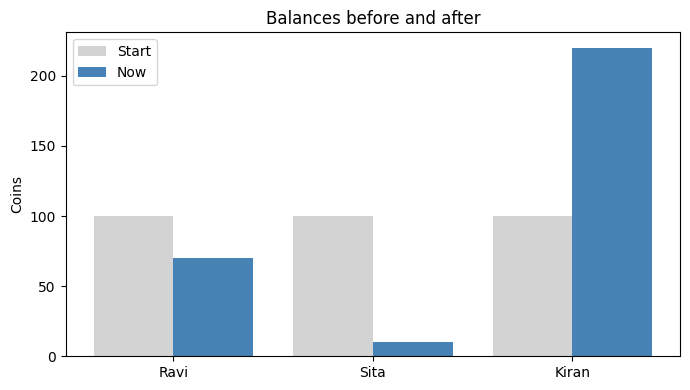

In [3]:
import matplotlib.pyplot as plt

def audit(led):
    bal = {n: 100 for n in keys}
    nonce = {n: 0 for n in keys}
    for i, tx in enumerate(led):
        s = tx["sender"]
        try:
            pubs[s].verify(bytes.fromhex(tx["sig"]), payload(tx))
        except InvalidSignature:
            return f"FAILED at tx {i}: bad signature"
        if tx["nonce"] != nonce[s]:
            return f"FAILED at tx {i}: wrong nonce"
        if not (0 < tx["amount"] <= bal[s]):
            return f"FAILED at tx {i}: amount or balance"
        bal[s] -= tx["amount"]
        bal[tx["to"]] += tx["amount"]
        nonce[s] += 1
    return "PASSED" if bal == balances else "FAILED: balances differ"

print("Balances:", balances)
print("Total coins:", sum(balances.values()), "(started with 300)")
print("Any negative balance:", any(v < 0 for v in balances.values()))
print("Accepted transactions in ledger:", len(ledger))
print("\nAudit from scratch:", audit(ledger))

edited = copy.deepcopy(ledger)
edited[0]["amount"] = 1
print("Audit after editing a transaction:", audit(edited))
print("Audit after deleting a transaction:", audit(ledger[1:]))

names = list(balances)
x = list(range(len(names)))
plt.figure(figsize=(7, 4))
plt.bar([i - 0.2 for i in x], [100] * len(names), width=0.4, label="Start", color="lightgray")
plt.bar([i + 0.2 for i in x], [balances[n] for n in names], width=0.4, label="Now", color="steelblue")
plt.xticks(x, names)
plt.ylabel("Coins")
plt.title("Balances before and after")
plt.legend()
plt.tight_layout()
plt.show()